<hr style="border:2px solid #CC00FF;">

<div style="display:flex; justify-content:center; align-items:center; gap:25px; flex-wrap:nowrap; margin:5px 0;">
    <a href="https://medellin.unal.edu.co" target="_blank">
        <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA"
             style="height:60px; width:auto; max-width:150px; object-fit:contain;" alt="Logo UNAL">
    </a>
    <a href="https://minaslap.net/?redirect=0" target="_blank">
        <img src="https://minaslap.net/pluginfile.php/1/core_admin/logo/0x200/1770226238/Logo%20MinasLAP-3%20%281%29.png"
             style="height:60px; width:auto; max-width:180px; object-fit:contain;" alt="Logo MinasLAP">
    </a>
    <a href="https://micampus.unal.edu.co" target="_blank">
        <img src="https://micampus.unal.edu.co/pluginfile.php/1/theme_almondb/sliderimage1/1788871931/Slider_1.png"
             style="height:60px; width:auto; max-width:200px; object-fit:contain;" alt="Logo MiCampus">
    </a>
</div>

<h2 align="center" style="font-size:1.4em; margin:6px 0;">Deep Learning 2026-2S</h2>
<h3 align="center" style="font-size:1.05em; margin:4px 0;">WorkShop 2 - Clasificación de dígitos usando redes convolucionales y Keras</h3>
<h4 align="center" style="font-size:0.9em; margin:4px 0; color:#555;">Semana 2</h4>

<p align="center" style="font-size:0.82em; line-height:1.3; margin:6px 0;">
Departamento de Ciencias de la Computación y de la Decisión<br>
Facultad de Minas · Universidad Nacional de Colombia<br>
Docente: John R. Ballesteros
</p>

<hr style="border:1px solid #CC00FF; margin:8px 0;">

<p style="font-size:0.78em; line-height:1.35; margin:4px 0;"><b>Equipo de trabajo:</b></p>

<table style="width:100%; font-size:0.72em; line-height:1.25; border-collapse:collapse;">
  <tr>
    <td style="padding:2px 6px;">• Lissy Grace Restrepo Taborda</td>
    <td style="padding:2px 6px;">📧 <i>lrestrepopo@unal.edu.co </i></td>
    <td style="padding:2px 6px;">• Kelly Y. Monsalve Carvajal</td>
    <td style="padding:2px 6px;">📧 <i>kemonsalvec@unal.edu.co</i></td>
  </tr>
  <tr>
    <td style="padding:2px 6px;">• Leidy M. Castaño Hernández</td>
    <td style="padding:2px 6px;">📧 <i>lmcastanoh@unal.edu.co</i></td>
    <td style="padding:2px 6px;">• Kevin F. Hidalgo Higuita</td>
    <td style="padding:2px 6px;">📧 <i>kfhidalgoh@unal.edu.co</i></td>
  </tr>
  <tr>
    <td style="padding:2px 6px;">• Sebastian Sánchez Arango</td>
    <td style="padding:2px 6px;">📧 <i>sebsanchezar@unal.edu.co</i></td>
  </tr>
</table>

<p align="center" style="font-size:0.75em; margin:8px 0 0 0;">
📅 04 de Noviembre de 2026 ·
<a href="https://github.com/KevinHidalgoDS/deep-learning-ws">
  <img src="https://img.shields.io/badge/repository-GitHub-181717.svg" alt="GitHub Repo" style="vertical-align:middle;">
</a>
</p>

<p align="center" style="font-size:0.68em; color:#777; margin:4px 0 0 0;">
<i>Nota: el tema del navegador puede afectar la visualización de la presentación.</i>
</p>

In [1]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils import logger as log

logger = log.LOGGER
config = log.CONFIG
plt.rc('figure', figsize=(16, 9))
plt.rc('font', size=14)
plt.style.use("ggplot")
sns.set_theme(style="darkgrid")
logger.info("Python %s on %s", sys.version, sys.platform)

2026-11-05 17:14:58 [INFO] Python 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)] on win32


# Clasificación de dígitos usando Redes Convolucionales y Keras

## 1 - El set de datos

En este tutorial implementaremos una red convolucional para clasificar los dígitos del 0 al 9. Para ello usaremos el set de datos [MNIST](https://www.kaggle.com/datasets/hojjatk/mnist-dataset), que contiene un total de 70.000 imágenes escritas a mano por diferentes personas.



Al final de este tutorial tendremos claro:
1. Cómo funciona [LeNet-5](https://www.kaggle.com/code/blurredmachine/lenet-architecture-a-complete-guide), la red convolucional usada en este tutorial
2. Cómo implementar esta red convolucional usando la librería Keras
3. Cómo evaluar el desempeño de la red


## 2 - LeNet-5

Esta red es la precursora de todas las redes convolucionales usadas en la actualidad. Fue diseñada por [Yann LeCun] a finales de los años 90, con el fin de clasificar dígitos (del 0 al 9) escritos a mano.

Esta red tiene como entradas imágenes de 28x28x1: 28 filas, 28 columnas y 1 sólo canal de color, es decir imágenes en escala de gris.


Como se observa en la figura de arriba, la red cuenta con dos bloques de procesamiento:
- Las *capas convolucionales* que se encargan de extraer características de las imágenes
- Una *red neuronal* fully connected, que toma dichas características y permite clasificar la imagen en uno de los posibles 10 dígitos (del 0 al 9)

Además, podemos observar las siguientes características:
- Después de realizar convoluciones se usa siempre la función de activación *ReLU*
- El *max-pooling* (obtencion del valor mayor) se realiza después de las convoluciones
- Las *dimensiones espaciales* (número de filas y columnas) de las imágenes se reducen entre una capa y otra, mientras que la profundidad (correspondiente a las características extraídas) aumenta entre una capa y otra

Las redes convolucionales usadas en la actualidad implementan una lógica similar a la de LeNet-5.

## 3 - Implementación en Keras

### 3.1 - Librerías requeridas

En primer lugar se importa la librería Numpy y se ajusta la semilla del generador aleatorio para garantizar la reproducibilidad del entrenamiento. También importaremos la librería Matplotlib, para poder visualizar las imágenes del set de datos :

In [2]:
import numpy as np
np.random.seed(2)

import matplotlib.pyplot as plt
%matplotlib inline

A continuación importamos las funciones *Sequential*, *Conv2D*, *MaxPooling2D*, *Flatten*, *Dense* y *SGD* de Keras:

In [3]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import SGD

### 3.2 - Pre-procesamiento del set de datos

La función *mnist* de Keras permite leer el set de datos y crear automáticamente los sets de entrenamiento y validación. El primero de ellos tendrá 60,000 imágenes (cada una de 28x28) con sus correspondientes categorías, mientras que el segundo tendrá 10,000 datos:

In [4]:
(x_train, y_train), (x_test,y_test) = mnist.load_data()
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 
(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


Los pixeles en las imágenes (tanto de entrenamiento como de validación) tienen valores entre 0 y 255; sin embargo, para garantizar la convergencia del entrenamiento es necesario normalizar estos valores entre 0 y 1:

In [5]:
# 8 bits significa
mybits = 2*2*2*2*2*2*2*2
print(mybits)

256


In [6]:
x_train = x_train/255.0
x_test = x_test/255.0

También se deben codificar *y_train* y *y_test* en el formato *one-hot*:

In [7]:
#1 hot encoding: 1 0 0 0 0 0 0...
# 0 1 0 0 0 0

nclases = 10
y_train = to_categorical(y_train,nclases)
y_test = to_categorical(y_test,nclases)

Finalmente, podemos visualizar un ejemplo de imagen dentro del dataset:

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

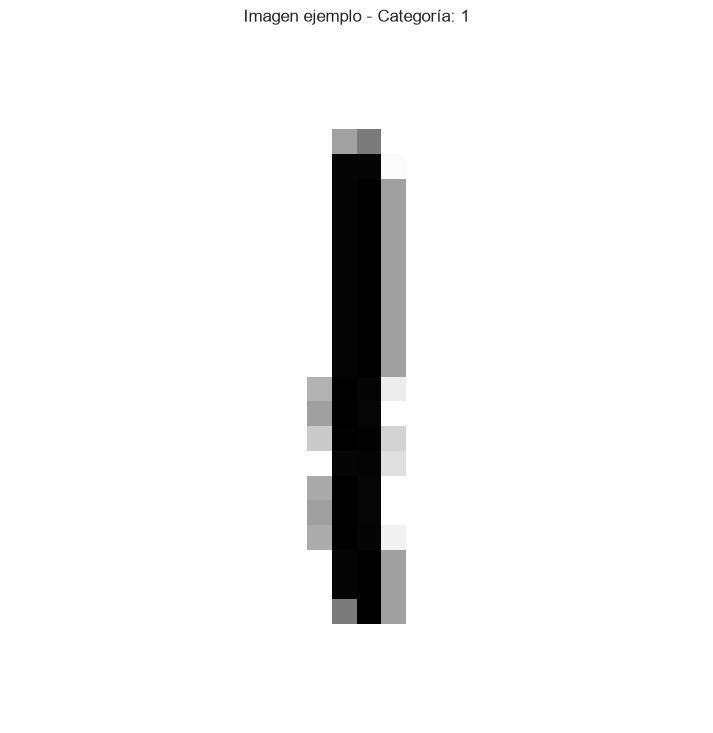

In [8]:
nimagen = 102 #99 #71
plt.imshow(x_train[nimagen,:].reshape(28,28), cmap='gray_r')
plt.title('Imagen ejemplo - Categoría: ' + str(np.argmax(y_train[nimagen])))
plt.axis('off')

Por defecto, Keras requiere cada dato de entrada en el formato nimagenes x nfilas x ncolumnas x ncanales, donde ncanales = 1 por ser imágenes en escala de gris. Se debe modificar el tamaño de *x_train* y *x_test* para cumplir con este requerimiento:

In [9]:
x_train = x_train.reshape(60000,28,28,1)
x_test = x_test.reshape(10000,28,28,1)

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


### 3.3 - Creación del modelo

En la siguiente tabla se resumen las características de cada capa a implementar:
    
| **Capa**          | **Características**                            |
|-------------------|------------------------------------------------|
| CONV 1            | 6 filtros, 5x5, p=0, s=1, activación: ReLU     |
| MAX-POOLING 1     | 6 filtros, 2x2, p=0, s=2, activación: Ninguna  |
| CONV 2            | 16 filtros, 5x5, p=0, s=1, activación: ReLU    |
| MAX-POOLING 2     | 16 filtros, 2x2, p=0, s=2, activación: Ninguna |
| FLATTEN           | Simplemente convierte una matriz en un vector  |
| FULLY CONNECTED 1 | 120 neuronas, activación: ReLU                 |
| FULLY CONNECTED 2 | 84 neuronas, activación: ReLU                  |
| SALIDA            | 10 categorías, activación: softmax (valor mayor de probabilidad)             |



Creemos el contenedor del modelo usando *Sequential()*:

In [10]:
modelo = Sequential()

Y añadimos, de forma secuencial, las diferentes capas de la red convolucional. En particular, usamos *Conv2D* para las capas convolucionales y *MaxPooling2D* para el *max-pooling*, junto con *Flatten* y *Dense* para la etapa de clasificación con redes neuronales y la capa de salida:

In [11]:
# CONV1 Y MAX-POOLING1
modelo.add(Conv2D(filters=6, kernel_size=(5,5), activation='relu', input_shape=(28,28,1)))
modelo.add(MaxPooling2D(pool_size=(2,2)))

# CONV2 Y MAX-POOLING2
modelo.add(Conv2D(filters=16, kernel_size=(5,5), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Aplanar, FC1, FC2 y salida
modelo.add(Flatten())
modelo.add(Dense(120,activation='relu'))
modelo.add(Dense(84,activation='relu'))
modelo.add(Dense(nclases,activation='softmax'))

D:\deep-learning-ws\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 3.4 - Compilación del modelo

En esta etapa definimos el optimizador a usar (gradiente descendente, tasa de aprendizaje = 0.1), así como la función de error (entropía cruzada) y la métrica de desempeño (precisión):

In [12]:
sgd = SGD(learning_rate=0.01) #0.1
modelo.compile(loss='categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

### 3.5 - Entrenamiento

Realicemos el entrenamiento usando 10 iteraciones, una tasa de aprendizaje de 0.1 y un tamaño de lote (*batch_size*) de 128:

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6643 - loss: 1.1381 - val_accuracy: 0.9010 - val_loss: 0.3462
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9072 - loss: 0.3103 - val_accuracy: 0.9280 - val_loss: 0.2387
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9320 - loss: 0.2233 - val_accuracy: 0.9394 - val_loss: 0.1910
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9453 - loss: 0.1789 - val_accuracy: 0.9517 - val_loss: 0.1576
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9533 - loss: 0.1513 - val_accuracy: 0.9591 - val_loss: 0.1337
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9593 - loss: 0.1321 - val_accuracy: 0.9639 - val_loss: 0.1160
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9635 - loss: 0.1179 - val_accuracy: 0.9685 - val_loss: 0.1036
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9669 - loss: 0.1070 - val_accuracy: 0.

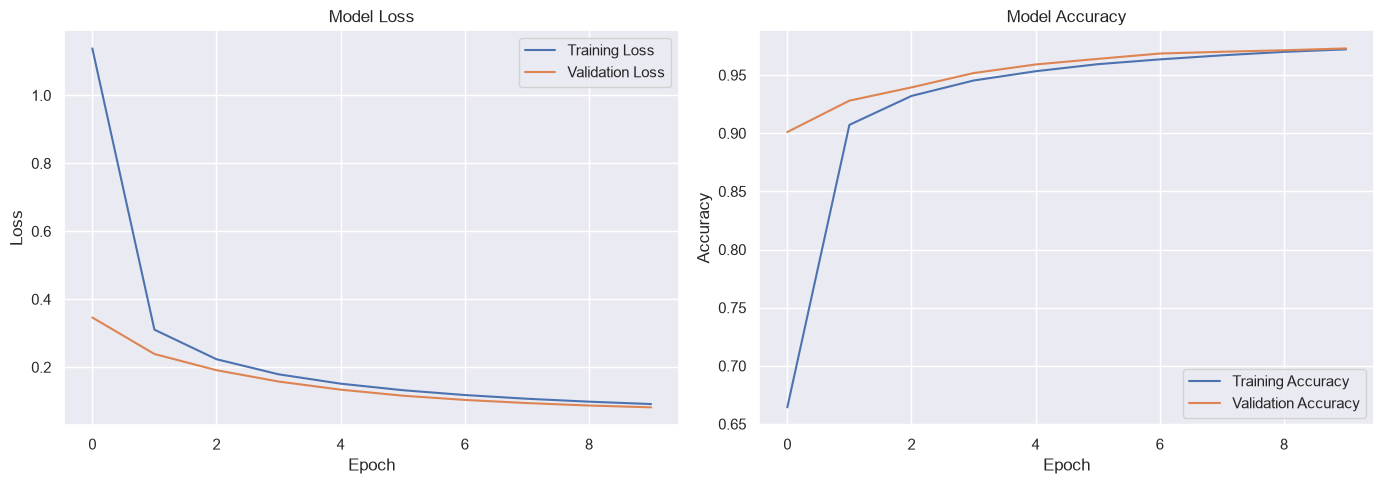

In [13]:
import matplotlib.pyplot as plt

# Training parameters
nepochs = 10
tam_lote = 128  # batch size

# Train the model and save history
history = modelo.fit(x_train, y_train, epochs=nepochs, batch_size=tam_lote, verbose=1, validation_data=(x_test, y_test))

# Plotting training & validation loss values
plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


Vemos que en la última iteración, el modelo alcanza una exactitud de 99.3% para el set de entrenamiento y del 98.6% para el set de validación. Esto indica que, en promedio, de cada 100 datos, aproximadamente 1 a 2 son clasificados incorrectamente. !Nada mal!

## 4 - Desempeño del modelo

El valor obtenido anteriormente es una medida de desempeño global de la red convolucional en el entrenamiento, pero no nos permite verificar si algunos dígitos resultan mejor clasificados que otros. Para analizar en detalle este comportamiento, podemos usar la matriz de confusión sobre el dataset de test:

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


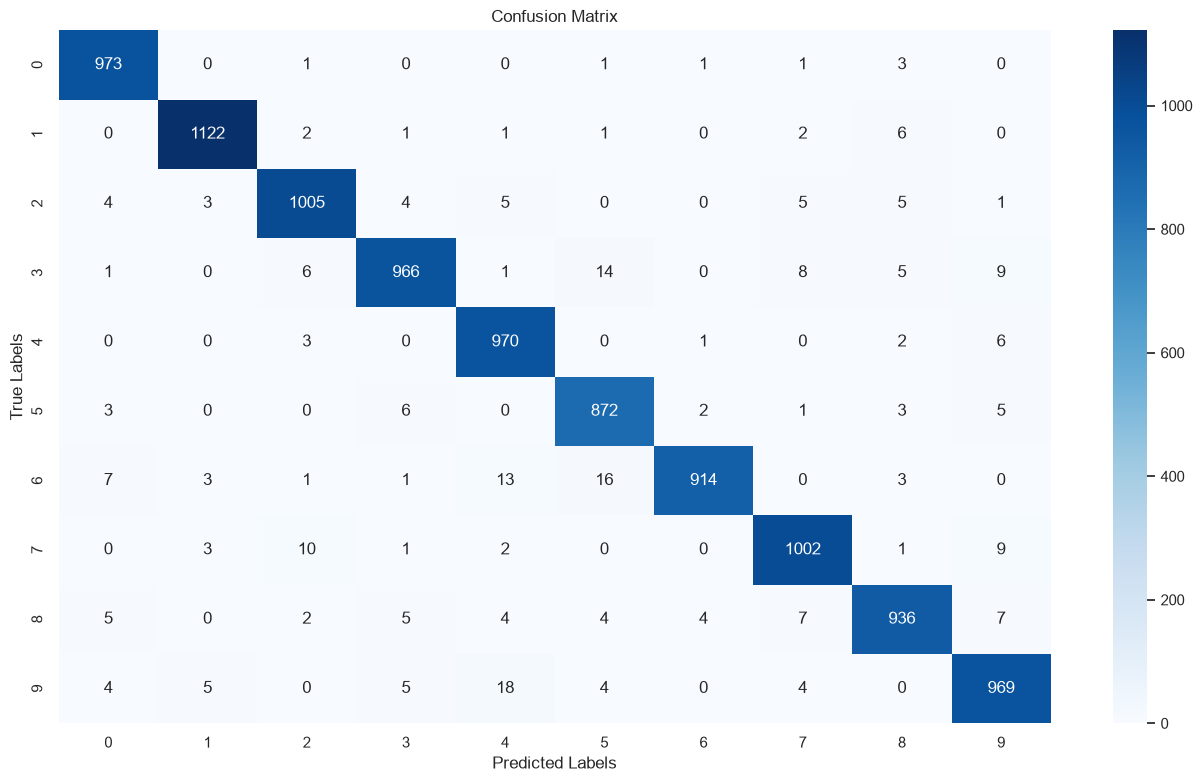

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Get predictions and convert them to class labels
y_pred = np.argmax(modelo.predict(x_test), axis=1)
y_ref = np.argmax(y_test, axis=1)

# Define class labels
etiquetas = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

# Calculate confusion matrix
conf_matrix = confusion_matrix(y_ref, y_pred, labels=range(10))

# Plot the confusion matrix with labels
# plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()


# Transfer Learning

Consiste en usar un modelo pre-entrenado en un conjunto de imagenes, mientras mas similares mejor (pero puede ser de otro tipo u objetos), y dejar fijo la primera parte de la red neuronal convolucional (el extractor de caracteristicas), entrenando solo el clasificador o las capas de salida con base en el dataset de interes.

Generalmente el modelo pre-entrenado es grande (profundo) y por tanto se necesitan menos epocas de entrenamiento que un modelo no pre-entrenado.


In [ ]:
!pip install h5py

In [15]:
import tensorflow as tf
print(tf.__version__)

2.22.0-rc0


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 39s 227ms/step - accuracy: 0.4578 - loss: 2.2229 - val_accuracy: 0.6410 - val_loss: 1.0022
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 230ms/step - accuracy: 0.8486 - loss: 0.4259 - val_accuracy: 0.9170 - val_loss: 0.2603
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 229ms/step - accuracy: 0.9544 - loss: 0.1494 - val_accuracy: 0.9350 - val_loss: 0.2116
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 228ms/step - accuracy: 0.9808 - loss: 0.0715 - val_accuracy: 0.9250 - val_loss: 0.2258
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 36s 228ms/step - accuracy: 0.9912 - loss: 0.0376 - val_accuracy: 0.9430 - val_loss: 0.1726


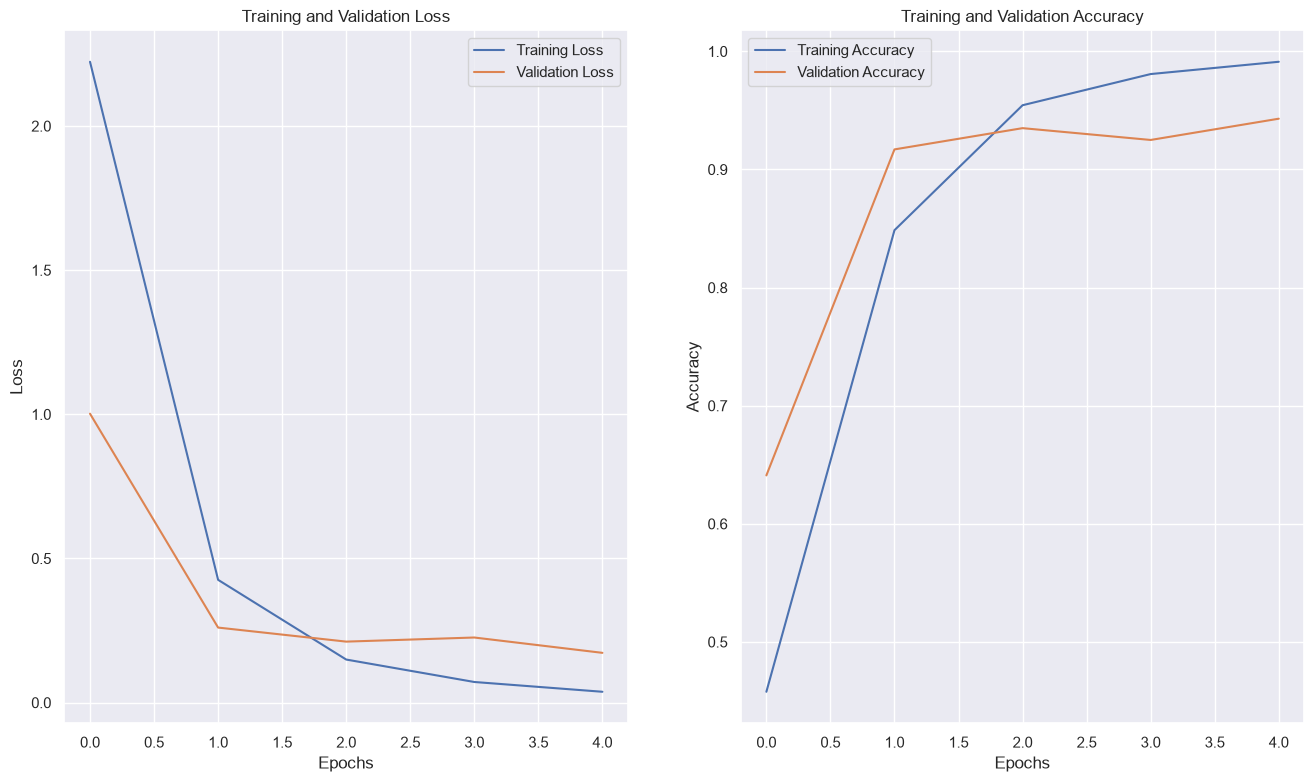

In [16]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train[..., tf.newaxis].astype("float32") / 255.0
x_test = x_test[..., tf.newaxis].astype("float32") / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Reduce dataset to avoid RAM crash
x_train, y_train = x_train[:5000], y_train[:5000]
x_test, y_test = x_test[:1000], y_test[:1000]

# Resize to 224 and convert to RGB
x_train = tf.image.grayscale_to_rgb(tf.image.resize(x_train, (224, 224)))
x_test = tf.image.grayscale_to_rgb(tf.image.resize(x_test, (224, 224)))

# Pretrained base model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)


base_model.trainable = False

# Build model
inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = Flatten()(x)
x = Dense(120, activation="relu")(x)
x = Dense(84, activation="relu")(x)
outputs = Dense(10, activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(optimizer=SGD(learning_rate=0.01),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(x_train, y_train, epochs=5, batch_size=32,
                    validation_data=(x_test, y_test))

# Plot training & validation loss values
# plt.figure(figsize=(14, 5))

# Plot loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

# Optimizadores

El mas usado es Adam con o sin variable learning rate y momentum. The Adam optimizer in Keras defaults to an initial learning rate of 0.001, beta_1 of 0.9 (the equivalent of momentum), and beta_2 of 0.999 for the second moment. These values generally work well for a variety of tasks.

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 798ms/step - accuracy: 0.9368 - loss: 0.2384 - val_accuracy: 0.9500 - val_loss: 0.1908
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 28s 688ms/step - accuracy: 0.9944 - loss: 0.0227 - val_accuracy: 0.9550 - val_loss: 0.1504
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 29s 716ms/step - accuracy: 0.9986 - loss: 0.0091 - val_accuracy: 0.9580 - val_loss: 0.1482
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 31s 776ms/step - accuracy: 0.9996 - loss: 0.0048 - val_accuracy: 0.9590 - val_loss: 0.1474
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 31s 771ms/step - accuracy: 0.9998 - loss: 0.0034 - val_accuracy: 0.9620 - val_loss: 0.1535


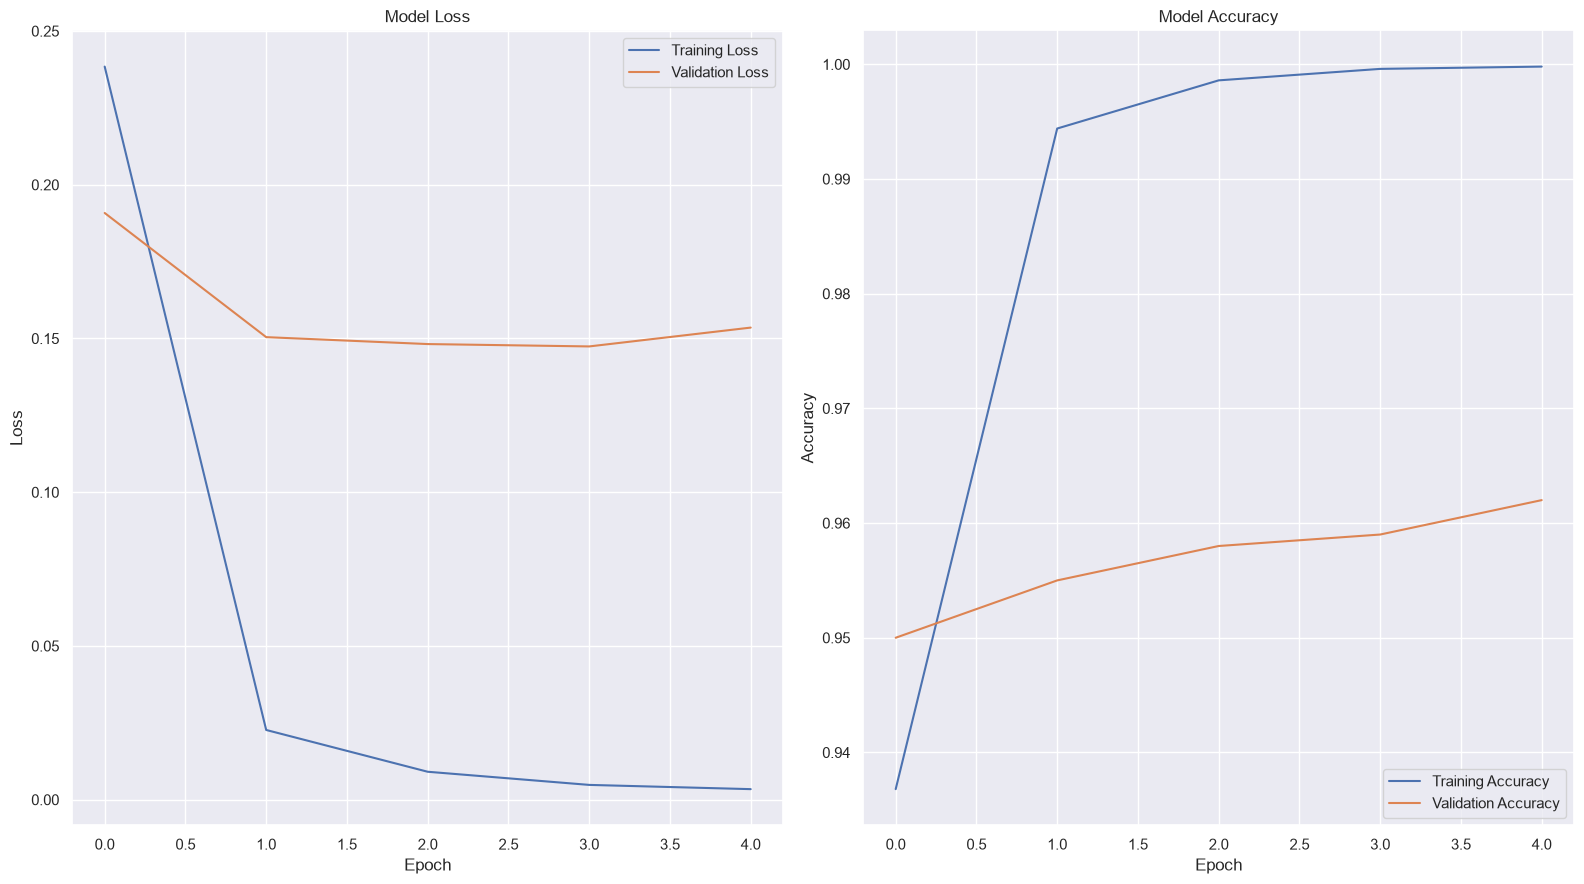

In [17]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Customize learning rate and beta_1 (momentum)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)

# Compile the model with Adam
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model and save history
history = model.fit(x_train, y_train, epochs=5, batch_size=128, validation_data=(x_test, y_test))

# Plot training & validation loss values
# plt.figure(figsize=(12, 4))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()


Why Categorical cross-entropy?

It is used in classification tasks (including multi-class like Mnist) because it calculates the difference between the predicted probability distribution and the true distribution.

Categorical cross-entropy is computed as
−
∑
(
𝑦
log
⁡
(
𝑦
^
)
)
−∑(ylog(
y
^
​
 )), where
𝑦
y is the true label (one-hot encoded) and
𝑦
^
y
^
​
  is the predicted probability from the model. This formula incorporates the exponential nature of the softmax function, which maps logits (raw model outputs) to probabilities by converting them into exponential values and normalizing them to sum to one.
